[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/recsys/03-baselines.ipynb)

# Baselines: Popularity and Item-Item Similarity

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Build popularity recommenders and show why a plain average rating is a bad one.</li>
<li>Compute item-item cosine similarity with shrinkage and recommend from it.</li>
<li>Tune a model on a validation split that sits inside the training data, then touch the test set once.</li>
<li>Explain why a validation gain can shrink on the test set.</li>
</ul>
</div>

**Prerequisites:** [Splitting and ranking metrics](02-split-and-metrics.ipynb). **Dataset:** MovieLens small. **Time:** about 35 minutes.

## The situation

Before anything clever, the question is: **what is the cheapest recommender that is not embarrassing?** Two answers are standard. *Show everyone what is popular.* And *show each user items similar to what they already have.* Everything later in this track has to beat these two, and "beat" means by an amount the data can distinguish from noise (page 2).

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import load_movielens, recsys as rs, style

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.float_format", "{:,.4f}".format)

## Maths ↔ code

- **Popularity:** $s_i = |\{u : r_{ui} \neq 0\}|$, the number of users who rated item $i$. In code: `rs.popularity(B)`.
- **Damped mean:** $\hat{r}_i = \dfrac{\sum_u r_{ui} + d\,\mu}{n_i + d}$, with $n_i$ ratings, global mean $\mu$, damping $d$. In code: `rs.damped_mean(X, d)`.
- **Item-item cosine:** with $U_i$ the set of users who have item $i$,

$$\text{sim}(i,j) = \dfrac{|U_i \cap U_j|}{\sqrt{|U_i|\,|U_j|}}\cdot\dfrac{n_{ij}}{n_{ij}+\lambda}$$

where $n_{ij}=|U_i\cap U_j|$ and $\lambda$ is the **shrinkage**. Only the $k$ most similar items to each item are kept. In code: `rs.item_similarity(B, k, shrink)`.
- **Score of item $j$ for user $u$:** $\sum_{i \in I_u} \text{sim}(i,j)$, the similarity-weighted votes of the items the user has. In code: `rs.item_knn_scores(B, S)`.

## 0. The protocol, and a validation split

We tune choices (damping, $k$, shrinkage) on a **validation split carved out of the training data**, in the same time-ordered way, and look at the real test split once at the end. Tuning on the test set would give a flattering number, as on the time-series pages.

In [2]:
ml = load_movielens()
ratings, movies = ml.ratings, ml.movies
title = movies.set_index("movieId")["title"]

task = rs.make_task(ratings)                              # test = each user's latest 20%
val = rs.make_task(task.train, index=task.index)          # validation = the latest 20% of what is left
n_users, n_items = task.X.shape

def ndcg(scores, t):                                       # mean NDCG@10 over scored users
    return rs.evaluate(scores, t.B, t.relevant)["ndcg"].mean()

print(f"validation task: train on {len(val.train):,}, validate on {len(val.test):,} ratings ({val.relevant.nnz:,} hits)")
print(f"test task:       train on {len(task.train):,}, test on {len(task.test):,} ratings ({task.relevant.nnz:,} hits)")

validation task: train on 64,549, validate on 16,123 ratings (7,305 hits)
test task:       train on 80,672, test on 20,164 ratings (9,358 hits)


## 1. Popularity, and its rating-based cousins

Three ways to turn the training ratings into one list for everybody: count the ratings, count only the *likes* (4 stars or more), or use the mean rating. The mean feels the most natural ("recommend the best-rated movies"), so look at what it recommends first.

In [3]:
count = np.asarray(val.B.sum(axis=0)).ravel()
plain_mean = rs.damped_mean(val.X, damping=0)             # damping 0 = the ordinary mean
damped = rs.damped_mean(val.X, damping=30)

def show_top(score, n=5):
    best = np.argsort(-score, kind="stable")[:n]
    return pd.DataFrame({"movie": [title[task.index.items[i]][:42] for i in best],
                         "score": score[best].round(2), "ratings": count[best].astype(int)})

print("Top 5 by plain mean rating:"); display(show_top(plain_mean))
print("Top 5 by damped mean (d = 30):"); display(show_top(damped))

Top 5 by plain mean rating:


,movie,score,ratings
0,"Cry, the Beloved Country (1995)",5.0000,1
1,Heidi Fleiss: Hollywood Madam (1995),5.0000,2
2,"Awfully Big Adventure, An (1995)",5.0000,1
3,"Umbrellas of Cherbourg, The (Parapluies de",5.0000,1
4,"Colonel Chabert, Le (1994)",5.0000,1


Top 5 by damped mean (d = 30):


,movie,score,ratings
0,"Shawshank Redemption, The (1994)",4.3200,259
1,Fight Club (1999),4.1800,175
2,"Godfather, The (1972)",4.1700,157
3,Star Wars: Episode IV - A New Hope (1977),4.1300,212
4,"Godfather: Part II, The (1974)",4.1300,97


The five best-**rated** movies by the plain mean are movies that **one or two people** rated 5 stars: a score of exactly 5.0 resting on 1 or 2 ratings. Nobody else has seen them, so nothing says the next user will like them. The damped mean pulls uncertain means toward the overall mean, and its top five are acclaimed, widely seen films (97 to 259 ratings each).

,validation NDCG@10
random,0.0010
plain mean rating,0.0003
"damped mean, d = 30",0.0658
"damped mean, d = 1000",0.0772
number of likes,0.0786
number of ratings (popularity),0.0799


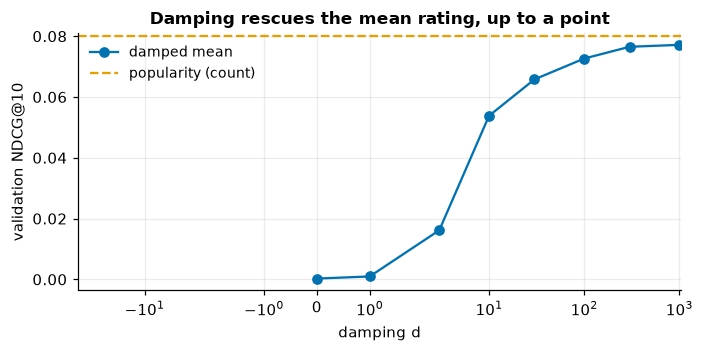

In [4]:
random_scores = np.random.default_rng(0).random(val.B.shape)
liked_count = np.asarray((val.X >= 4).sum(axis=0)).ravel().astype(np.float32)

sweep = {d: ndcg(rs.broadcast(rs.damped_mean(val.X, d), n_users), val) for d in (0, 1, 3, 10, 30, 100, 300, 1000)}
validation = pd.Series({
    "random": ndcg(random_scores, val),
    "plain mean rating": sweep[0],
    "damped mean, d = 30": sweep[30],
    "damped mean, d = 1000": sweep[1000],
    "number of likes": ndcg(rs.broadcast(liked_count, n_users), val),
    "number of ratings (popularity)": ndcg(rs.broadcast(rs.popularity(val.B), n_users), val),
}, name="validation NDCG@10")
assert validation["plain mean rating"] < 0.005 and validation["number of ratings (popularity)"] == validation.max()
display(validation.to_frame())

fig, ax = plt.subplots(figsize=(6.5, 3.3))
ax.plot(list(sweep), list(sweep.values()), marker="o", color=style.BLUE, label="damped mean")
ax.axhline(validation["number of ratings (popularity)"], color=style.ORANGE, ls="--", label="popularity (count)")
ax.set(xscale="symlog", xlabel="damping d", ylabel="validation NDCG@10", title="Damping rescues the mean rating, up to a point")
ax.legend(); plt.tight_layout(); plt.show()

The plain mean scores **0.0003, no better than a random list (0.0010)**: its whole top of the list is made of one-rating movies. Damping rescues it, and the more the better (0.066 at d = 30, 0.077 at d = 1000), but the curve climbs toward, and never passes, the simple **count of ratings (0.0799)**. That is no accident: with a very large damping, ranking by the damped mean is ranking by *number of ratings times how far the mean is above average*, so it turns into a popularity count. On this data the plain count is as good as any non-personalised score, so it is the **popularity baseline** used from here on.

## 2. Item-item similarity

Popularity gives everybody the same list. **Item-item** collaborative filtering personalises it using one idea: *movies that the same people rate are related.* Two movies are similar if many users have both, normalised so that blockbusters do not look similar to everything. Then a user's score for a movie is the total similarity between it and the movies the user already has.

First, check the similarities by eye. Here are the nearest neighbours of one well-known and one obscure movie, with and without shrinkage:

In [5]:
B = task.B
n_ratings = np.asarray(B.sum(axis=0)).ravel()
cols = {name: np.flatnonzero(task.index.items == movies.loc[movies["title"].str.startswith(name), "movieId"].iloc[0])[0]
        for name in ["Toy Story (1995)"]}
obscure = int(np.flatnonzero(n_ratings == 10)[0])          # the first movie with exactly 10 training ratings
cols[title[task.index.items[obscure]]] = obscure

def neighbours(item, shrink, n=5):
    sim = rs.item_similarity(B, k=10, shrink=shrink)[item].toarray().ravel()
    best = np.argsort(-sim)[:n]
    return [f"{title[task.index.items[i]][:30]} ({sim[i]:.2f}, {int(n_ratings[i])} ratings)" for i in best]

for name, item in cols.items():
    print(f"\n{name[:45]}: {int(n_ratings[item])} ratings")
    for shrink in (0, 50):
        print(f"  shrinkage {shrink:>2}:", " | ".join(neighbours(item, shrink)))


Toy Story (1995): 201 ratings


  shrinkage  0: Independence Day (a.k.a. ID4)  (0.59, 178 ratings) | Jurassic Park (1993) (0.57, 222 ratings) | Star Wars: Episode IV - A New  (0.56, 237 ratings) | Forrest Gump (1994) (0.56, 304 ratings) | Mission: Impossible (1996) (0.55, 139 ratings)


  shrinkage 50: Forrest Gump (1994) (0.41, 304 ratings) | Independence Day (a.k.a. ID4)  (0.40, 178 ratings) | Jurassic Park (1993) (0.40, 222 ratings) | Star Wars: Episode IV - A New  (0.40, 237 ratings) | Star Wars: Episode VI - Return (0.36, 177 ratings)

Cutthroat Island (1995): 10 ratings


  shrinkage  0: Boys on the Side (1995) (0.46, 12 ratings) | Human Traffic (1999) (0.45, 2 ratings) | Crooklyn (1994) (0.45, 2 ratings) | Mad Love (1995) (0.45, 2 ratings) | Bright Lights, Big City (1988) (0.45, 2 ratings)


  shrinkage 50: Boys on the Side (1995) (0.04, 12 ratings) | Heavy Metal (1981) (0.04, 25 ratings) | Three Musketeers, The (1993) (0.04, 47 ratings) | GoldenEye (1995) (0.04, 123 ratings) | Don Juan DeMarco (1995) (0.04, 29 ratings)


For **Toy Story**, which 201 users have rated, the neighbours are blockbusters rated by 139 to 304 users, and shrinkage only rescales their similarities (0.59 becomes 0.40). The obscure movie tells the real story. Without shrinkage its closest neighbours are movies with **2 ratings each** and a similarity of about 0.45: a pair of movies "seen by the same one or two people" looks nearly as related as anything can. With shrinkage of 50 those coincidences vanish: all its similarities drop to about 0.04 and the neighbours are movies with more ratings (12 to 123). Shrinkage turns "similar" into "similar, **and we have the evidence to say so**".

Now tune $k$ (how many neighbours to keep) and the shrinkage $\lambda$ **on the validation split**.

In [6]:
grid = pd.DataFrame({lam: {k: ndcg(rs.item_knn_scores(val.B, rs.item_similarity(val.B, k=k, shrink=lam)), val)
                           for k in (20, 50, 100, 200)} for lam in (0, 10, 50, 100, 200, 500)})
grid.index.name, grid.columns.name = "k", "shrinkage"
best_k, best_lam = grid.stack().idxmax()
print(f"best on validation: k = {best_k}, shrinkage = {best_lam}, NDCG@10 = {grid.loc[best_k, best_lam]:.4f}")
grid.style.format("{:.4f}").background_gradient(cmap="Blues", axis=None)

best on validation: k = 100, shrinkage = 50, NDCG@10 = 0.1105


shrinkage,0,10,50,100,200,500
k,,,,,,
20,0.0911,0.0927,0.0984,0.1013,0.1013,0.1036
50,0.0939,0.0986,0.1014,0.1031,0.1046,0.1044
100,0.0954,0.0996,0.1105,0.1084,0.1059,0.1066
200,0.0901,0.0984,0.1066,0.1067,0.1056,0.1066


Validation NDCG@10 runs from 0.090 to 0.1105 over the 24 settings, and all of them beat popularity on validation (0.0799). **Shrinkage helps at every k**: compare the first column (no shrinkage) with the others, a gain of 0.010 to 0.017. **k matters less**: results rise up to about 100 neighbours and then level off. The surface is flat near the top, with many cells between 0.103 and 0.110, so which cell comes out as "best" is partly luck. We take k = 100 and shrinkage 50 and move on.

## 3. The test set, once

Everything is now fixed; score the choices on the test split. Four models: popularity, the damped mean at the best damping we tried, the *untuned* item-item model (the first thing one would try, $k=50$, no shrinkage) and the tuned one.

In [7]:
def per_user(scores):
    return rs.evaluate(scores, task.B, task.relevant)["ndcg"]

untuned_S = rs.item_knn_scores(task.B, rs.item_similarity(task.B, k=50, shrink=0))
tuned_S = rs.item_knn_scores(task.B, rs.item_similarity(task.B, k=best_k, shrink=best_lam))
test = {
    "popularity": per_user(rs.broadcast(rs.popularity(task.B), n_users)),
    "damped mean (d = 1000)": per_user(rs.broadcast(rs.damped_mean(task.X, 1000), n_users)),
    "item-item, untuned (k=50, no shrinkage)": per_user(untuned_S),
    "item-item, tuned": per_user(tuned_S),
}
result = pd.DataFrame({"test NDCG@10": {name: s.mean() for name, s in test.items()}})
result["vs popularity"] = [None] + [f"{(d := rs.paired_difference(s, test['popularity']))['diff']:+.4f}  [{d['lo']:+.4f}, {d['hi']:+.4f}]" for s in list(test.values())[1:]]
display(result)
d_tuned = rs.paired_difference(test["item-item, tuned"], test["popularity"])
d_untuned = rs.paired_difference(test["item-item, untuned (k=50, no shrinkage)"], test["popularity"])
assert d_tuned["lo"] > 0 > d_untuned["lo"]                 # guards the reading below

tuned_vs_untuned = rs.paired_difference(test["item-item, tuned"], test["item-item, untuned (k=50, no shrinkage)"])
validation_gain = grid.loc[best_k, best_lam] - grid.loc[50, 0]
assert tuned_vs_untuned["lo"] < 0 < tuned_vs_untuned["hi"] and validation_gain > 2 * tuned_vs_untuned["diff"]
print(f"tuning gain: {validation_gain:+.4f} on validation, but {tuned_vs_untuned['diff']:+.4f} on test "
      f"(95% interval [{tuned_vs_untuned['lo']:+.4f}, {tuned_vs_untuned['hi']:+.4f}])")

,test NDCG@10,vs popularity
popularity,0.0743,NaN
damped mean (d = 1000),0.0774,"+0.0031 [-0.0021, +0.0082]"
"item-item, untuned (k=50, no shrinkage)",0.0852,"+0.0109 [-0.0022, +0.0240]"
"item-item, tuned",0.0913,"+0.0169 [+0.0053, +0.0286]"


tuning gain: +0.0167 on validation, but +0.0061 on test (95% interval [-0.0023, +0.0144])


Read the last column, the paired difference to popularity with its 95% interval.

- The **damped mean** (+0.003) is a tie: with a large damping it *is* popularity.
- The **untuned** item-item model is +0.011 ahead, but its interval **[-0.002, +0.024] contains zero**: on this test set it cannot be told apart from popularity.
- The **tuned** model is +0.017 ahead with an interval **[+0.005, +0.029] above zero**: a real, modest improvement.
- And yet the tuned model against the untuned one is a **tie** (+0.006, interval [-0.002, +0.014]). The tuning gain was 0.017 on validation and **0.006 on test**, about a third as large. Both "tuned beats popularity" and "tuned is not distinguishable from untuned" are true at once; the difference between "significant" and "not significant" is not itself significant.

## 4. What goes wrong: personalised, but narrow

A baseline that recommends the same ten movies to everyone is useless as a *product* even when its accuracy is respectable. How different are the lists, really?

In [8]:
top_pop = rs.top_k(rs.broadcast(rs.popularity(task.B), n_users), task.B, k=10)
top_knn = rs.top_k(tuned_S, task.B, k=10)
summary = pd.DataFrame({
    "distinct movies recommended": [len(np.unique(top_pop)), len(np.unique(top_knn))],
    "share of the catalogue": [rs.coverage(top_pop, n_items), rs.coverage(top_knn, n_items)],
}, index=["popularity", "item-item, tuned"])
assert summary.iloc[0, 0] < 110 and summary.iloc[1, 0] > 4 * summary.iloc[0, 0]
display(summary)

,distinct movies recommended,share of the catalogue
popularity,98,0.0101
"item-item, tuned",425,0.0437


Popularity recommends only **98 distinct movies** to all 610 users (1.0% of the catalogue), and its lists differ only because users have already rated some of the top titles. The tuned item-item model reaches **425** (4.4%). That is more personal, but 96% of the catalogue is never shown to anyone, and the movies it cannot show are those with too few ratings to have a reliable similarity (the cold-start problem of page 7). Page 8 measures this properly with *coverage* and *popularity bias*.

<div class="admonition warning">
<p class="admonition-title">Watch out</p>
<p>A tuning gain measured on validation is optimistic: you picked the winner <em>because</em> it scored best there. Expect part of the gain to evaporate on the test set, and report the test number with its interval, not the validation number.</p>
</div>

## Decision guide

| Situation | Use | Why |
|---|---|---|
| No history for the user, or a first release | Popularity (a **count**, not a mean rating) | Hard to beat, free, and the yardstick for everything else |
| You want to rank by quality | A **damped** mean, with a large damping | The plain mean is dominated by items with one or two ratings |
| Users have some history | Item-item with shrinkage | Cheap, explainable ("because you watched ..."), a strong baseline |
| Many more users than items | Item-item over user-user | The item-item similarity table is items by items, which stays small |

## Check yourself

<details class="question">
<summary>1. The plain mean rating gives NDCG about the same as a random list. Yet the mean rating of a movie is a real property of the movie. Why does it fail as a ranking score?</summary>

Because with few ratings the mean is mostly noise. Ranked by mean, the top of the list is filled with movies that one or two people rated 5 stars, and nobody else has seen them. A score has to be reliable where it is used, and the movies at the extremes are exactly the ones with the least evidence. Damping fixes this by pulling uncertain means toward the overall mean.

</details>

<details class="question">
<summary>2. What does shrinkage do to the similarity of two movies that only one user has in common?</summary>

It scales the similarity by $n/(n+\lambda)$ with $n = 1$ co-rater. For $\lambda = 50$ that multiplies it by 1/51, so a similarity that rests on a single person almost vanishes, while one that rests on 100 co-raters is barely changed. It encodes "do not trust a coincidence".

</details>

## Exercises

<details class="question">
<summary>Exercise 1 (easy): recommend ten movies from the item-item model for the user in row 0 and print the titles.</summary>

```python
row = tuned_S[0].copy()
row[task.B[0].nonzero()[1]] = -np.inf                      # never recommend what the user already rated
print([title[task.index.items[j]] for j in np.argsort(-row)[:10]])
```

The list is made of action and thriller blockbusters (The Terminator, Independence Day, Die Hard, ...). `rs.evaluate` hides the user's own items for you when it scores; when you display lists yourself, you must do it too.

</details>

<details class="question">
<summary>Exercise 2 (medium): popularity here ranks by the number of ratings. Does ranking by the number of <em>likes</em> (4 stars or more) do better on the test set?</summary>

```python
likes = np.asarray((task.X >= 4).sum(axis=0)).ravel().astype(np.float32)
alt = per_user(rs.broadcast(likes, n_users))
print(rs.paired_difference(alt, test["popularity"]))
```

On the validation split the two were within 0.002 of each other. On the test set counting likes comes out +0.003 ahead, with an interval of [-0.001, +0.008]: a tie. Check the interval before saying one is better.

</details>

<details class="question">
<summary>Exercise 3 (hard): the grid kept the best of 24 settings. Re-run the test comparison with a different grid (for example <code>k</code> in 10, 30, 60 and shrinkage in 5, 25, 75). Does the "tuned" model still beat the untuned one?</summary>

```python
grid2 = pd.DataFrame({lam: {k: ndcg(rs.item_knn_scores(val.B, rs.item_similarity(val.B, k=k, shrink=lam)), val)
                            for k in (10, 30, 60)} for lam in (5, 25, 75)})
k2, lam2 = grid2.stack().idxmax()
S2 = rs.item_knn_scores(task.B, rs.item_similarity(task.B, k=k2, shrink=lam2))
print(k2, lam2, rs.paired_difference(per_user(S2), test["item-item, untuned (k=50, no shrinkage)"]))
```

The second grid picks k = 60 and shrinkage 75 (validation 0.1056). Its test gain over the untuned model is +0.006 with an interval of [-0.002, +0.014]: the same small, unproven gain as before. When the gains from tuning are this small next to their interval, effort usually pays more on a better *kind* of model than on more tuning.

</details>

## Recap

- **Popularity by count** is the baseline to beat. A **plain mean rating ranks like a random list**; a heavily damped mean only gets close to the count.
- **Item-item cosine with shrinkage** personalises by "movies rated by the same people"; shrinkage keeps one coincidence from creating a "perfect" neighbour.
- **Tune on a validation split inside the training data**, then score the test split once.
- A gain from tuning is **optimistic on validation and smaller on test**; check the paired interval.
- Popularity reaches a tiny fraction of the catalogue, and even tuned item-item reaches only a small one. Page 8 returns to this.